# SL-PINN for the 2D-2V Vlasov-Poisson system -- JAX port



In [ ]:
import json
import os
import subprocess
import time
from pathlib import Path

import matplotlib
try:
    get_ipython  
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

GPU = os.environ.get("SLPINN_GPU")
if GPU is None:
    try:
        q = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.used,memory.total",
                            "--format=csv,noheader,nounits"],
                           capture_output=True, text=True, timeout=10).stdout
        free = [(int(t) - int(u), i) for i, u, t in
                (ln.split(", ") for ln in q.strip().splitlines())]
        GPU = str(max(free)[1])
        print(f"picked GPU {GPU} with {max(free)[0] / 1024:.1f} GiB free")
    except Exception:
        GPU = "0"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU

import jax
import jax.numpy as jnp
import jax.random as jr

import slpinn_2d2v_jax as sl

QUICK = False  
sl.use_paper_style()
print("jax devices:", jax.devices())

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print(f"quick = {QUICK}")


picked GPU 7 with 47.6 GiB free
jax devices: [CudaDevice(id=0)]
quick = False


## Training

The map is trained on the characteristic residual
$\partial_t\Psi + v\cdot\nabla_x\Psi + E\cdot\nabla_v\Psi = 0$, with $E$ solved
spectrally from $\rho=\int f\,dv$ at each iteration -- estimated on a **fixed,
small** $(\text{field\_nx})^2$ spatial grid crossed with importance-sampled
velocity nodes (Cranley-Patterson rotated Sobol points, resampled fresh every
step, entirely on-device). 

In [2]:
if QUICK:
    cfg = sl.TrainConfig(problem="gaussian_vp_2d", iters=300, n_slices=4, n_per_slice=64,
                         field_nx=8, field_nv=8, n_layers=4, width=32, depth=2,
                         n_velocity_nodes=32, log_every=50)
else:
    cfg = sl.TrainConfig(problem="gaussian_vp_2d", iters=1500, n_slices=4, n_per_slice=64,
                         field_nx=24, field_nv=24, n_layers=6, width=32, depth=2, lr=2.5e-3,
                         n_velocity_nodes=32, log_every=500)
    # cfg = sl.TrainConfig(problem="gaussian_vp_2d", iters=1000, n_slices=16, n_per_slice=512,
    #                      field_nx=24, field_nv=24, n_layers=8, width=64, depth=2,
    #                      n_velocity_nodes=128, log_every=200)

JAX_PATH = OUT / f"sl2d2v_jax_{'quick' if QUICK else 'paper'}"

trainer = sl.Trainer(cfg)
print(f"model params: {sl.n_params(trainer.model)}")
trainer.train()
trainer.save(JAX_PATH)
print(f"trained in {trainer.train_time:.1f}s -> {cfg.iters / trainer.train_time:.2f} it/s")


model params: 8856
[jax] iter      1  loss=1.237e+01  char=1.24e+01  energy=3.04e-03  ampere=1.18e-03  (0.1 it/s)
[jax] iter    500  loss=6.825e-03  char=6.77e-03  energy=4.37e-02  ampere=1.34e-05  (23.5 it/s)
[jax] iter   1000  loss=2.556e-03  char=2.52e-03  energy=1.84e-02  ampere=1.78e-05  (35.3 it/s)
[jax] iter   1500  loss=2.381e-03  char=2.38e-03  energy=8.92e-04  ampere=2.82e-06  (41.8 it/s)
trained in 35.9s -> 41.81 it/s


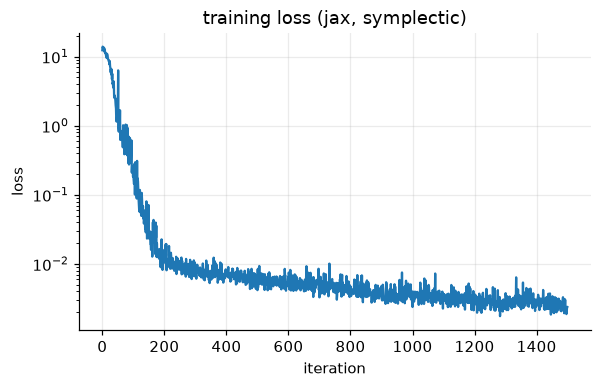

In [3]:
hist = np.array([r["loss"] for r in trainer.history])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(hist)
ax.set_xlabel("iteration"); ax.set_ylabel("loss")
ax.set_title("training loss (jax, symplectic)")
plt.show()


### Jacobian determinant

Measured directly in float64. For the symplectic map this should be one to
machine precision at any $(t, z)$ and for any trained parameters -- it is an
architectural guarantee (additive coupling layers), not something the loss
enforces.


In [4]:
det_rows = sl.det_statistics(trainer.model, trainer.problem,
                             jnp.linspace(0, trainer.problem.t_final, 3), n_points=512)
print(sl.markdown_table(det_rows, columns=["t", "median", "max"]))
det_max = max(r["max"] for r in det_rows)
assert det_max < 1e-6, det_max
print(f"\nmax |det - 1| = {det_max:.2e}  (unit Jacobian by construction)")


| t | median | max |
|---|---|---|
| 0 | 0 | 0 |
| 1 | 1.11e-16 | 6.661e-16 |
| 2 | 1.11e-16 | 6.661e-16 |

max |det - 1| = 6.66e-16  (unit Jacobian by construction)


## Reference solution

The Strang splitting semi-Lagrangian scheme (float64) with a GPU->CPU fallback on `RESOURCE_EXHAUSTED` (see the resolution-sweep section below for where that fallback actually gets exercised).


In [5]:
EVAL_N, EVAL_NT = (12, 3) if QUICK else (24, 5)
times = jnp.linspace(0, trainer.problem.t_final, EVAL_NT)
ref = sl.solve_reference(trainer.problem, nx=EVAL_N, nv=EVAL_N, dt=1 / 64,
                         save_times=[float(t) for t in times])
f_ref, xg, vg = ref.f, ref.x_grid, ref.v_grid

f_fn = trainer.f_fn()
f_mod = sl.evaluate_f_on_grids(f_fn, times.astype(sl.F32), [xg.astype(sl.F32), xg.astype(sl.F32),
                                                             vg.astype(sl.F32), vg.astype(sl.F32)])
print("reference grid:", f_ref.shape)


reference grid: (5, 24, 24, 24, 24)


## Accuracy vs the reference

Per-time relative $L^2$, $L^\infty$ and RMS error of $f$ on the evaluation grid.


In [6]:
err_rows = sl.error_table(f_mod.astype(sl.F64), f_ref, times)
print(sl.markdown_table(err_rows, columns=["t", "l2", "linf", ]))


| t | l2 | linf |
|---|---|---|
| 0 | 1.774e-10 | 6.421e-09 |
| 0.5 | 7.24e-05 | 0.00319 |
| 1 | 0.000124 | 0.0049 |
| 1.5 | 0.0001389 | 0.005396 |
| 2 | 0.0001371 | 0.005221 |


Phase-space projections at the final time: the charge density $\rho(x,y)$ and
the reduced distribution $f(x, v_x) = \int f\,dy\,dv_y$.


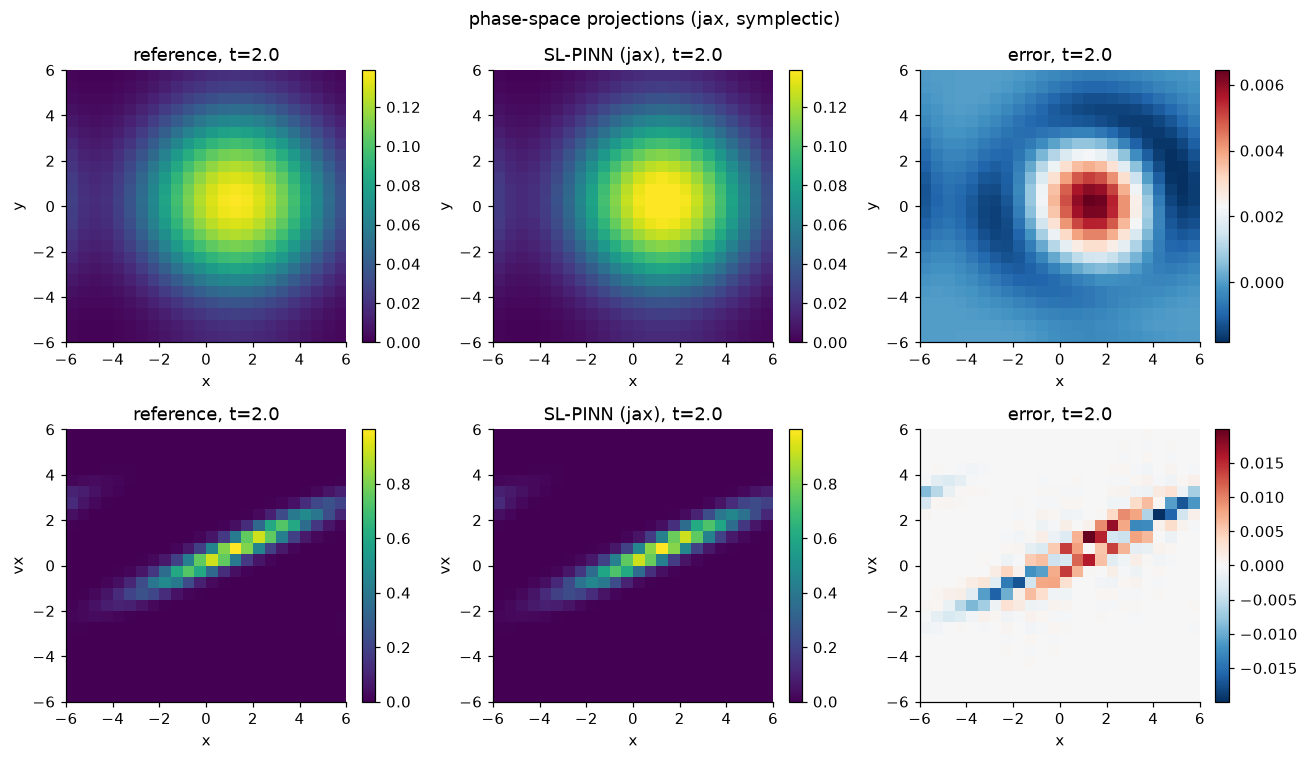

In [7]:
wv = sl.trapezoid_weights(vg)
dx = trainer.problem.length / len(xg)
i = len(times) - 1

rho_r = jnp.einsum("xyuw,u,w->xy", f_ref[i], wv, wv)
rho_m = jnp.einsum("xyuw,u,w->xy", f_mod[i].astype(sl.F64), wv, wv)
red_r = jnp.einsum("xyuw,w->xu", f_ref[i], wv) * dx
red_m = jnp.einsum("xyuw,w->xu", f_mod[i].astype(sl.F64), wv) * dx

p = trainer.problem
ext_xy = [p.x_lo, p.x_hi, p.x_lo, p.x_hi]
ext_xv = [p.x_lo, p.x_hi, p.v_lo, p.v_hi]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (a, b, ext, lab) in enumerate([(rho_r, rho_m, ext_xy, ("x", "y")),
                                        (red_r, red_m, ext_xv, ("x", "vx"))]):
    vmax = float(a.max())
    for ax, (data, title, cmap, kw) in zip(axes[row], [
            (a, "reference", "viridis", dict(vmin=0, vmax=vmax)),
            (b, "SL-PINN (jax)", "viridis", dict(vmin=0, vmax=vmax)),
            (b - a, "error", "RdBu_r", dict())]):
        im = ax.imshow(np.asarray(data).T, origin="lower", extent=ext, aspect="auto",
                       cmap=cmap, **kw)
        fig.colorbar(im, ax=ax, fraction=0.046)
        ax.set_title(f"{title}, t={float(times[i]):.1f}")
        ax.set_xlabel(lab[0]); ax.set_ylabel(lab[1]); ax.grid(False)
fig.suptitle("phase-space projections (jax, symplectic)")
fig.tight_layout()
plt.show()


## Conservation

Mass, momentum, total energy and $E_{\mathrm{rms}}$ over time, and their drift
from the initial value.


In [8]:
nt_c = 6 if QUICK else 11
tc = jnp.linspace(0, trainer.problem.t_final, nt_c)
ref_c = sl.solve_reference(trainer.problem, nx=EVAL_N, nv=EVAL_N, dt=1 / 64,
                          save_times=[float(t) for t in tc])
fr_c, xc, vc = ref_c.f, ref_c.x_grid, ref_c.v_grid
fm_c = sl.evaluate_f_on_grids(f_fn, tc.astype(sl.F32), [xc.astype(sl.F32), xc.astype(sl.F32),
                                                         vc.astype(sl.F32), vc.astype(sl.F32)])
lengths = (trainer.problem.length, trainer.problem.length)
cons_m = sl.conservation_from_f_grid_2d(fm_c.astype(sl.F64), tc, [xc, xc], [vc, vc],
                                        lengths, trainer.problem.has_field)
cons_r = sl.conservation_from_f_grid_2d(fr_c, tc, [xc, xc], [vc, vc],
                                        lengths, trainer.problem.has_field)

m0 = jnp.clip(jnp.abs(cons_m.mass[0]), 1e-30, None)
e0 = jnp.clip(jnp.abs(cons_m.energy[0]), 1e-30, None)
metrics = {
    "mode": "jax-symplectic",
    "params": sl.n_params(trainer.model),
    "final_rel_l2": err_rows[-1]["rel_l2"],
    "rel_mass_drift": float(jnp.max(jnp.abs(cons_m.mass - cons_m.mass[0])) / m0),
    "rel_energy_drift": float(jnp.max(jnp.abs(cons_m.energy - cons_m.energy[0])) / e0),
    "momentum_drift": float(jnp.max(jnp.abs(cons_m.momentum - cons_m.momentum[0]))),
    "train_time": trainer.train_time,
}
(OUT / f"metrics_2d2v_jax_{'quick' if QUICK else 'paper'}.json").write_text(json.dumps(metrics, indent=1))
print(sl.markdown_table([metrics], columns=["mode", "final_rel_l2", "rel_mass_drift",
                                            "rel_energy_drift", "momentum_drift"]))


| mode | final_rel_l2 | rel_mass_drift | rel_energy_drift | momentum_drift |
|---|---|---|---|---|
| jax-symplectic | 0.03949 | 9.08e-06 | 0.0153 | 0.009965 |


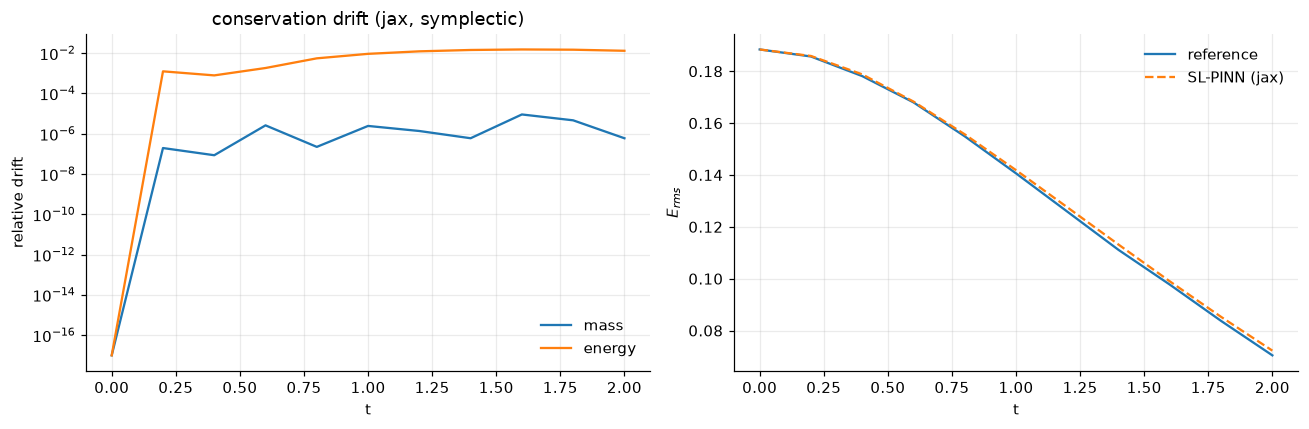

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(tc, jnp.clip(jnp.abs(cons_m.mass - cons_m.mass[0]) / m0, 1e-17, None), label="mass")
axes[0].semilogy(tc, jnp.clip(jnp.abs(cons_m.energy - cons_m.energy[0]) / e0, 1e-17, None), label="energy")
axes[0].set_xlabel("t"); axes[0].set_ylabel("relative drift")
axes[0].set_title("conservation drift (jax, symplectic)"); axes[0].legend()
axes[1].plot(tc, cons_r.e_rms, label="reference")
axes[1].plot(tc, cons_m.e_rms, "--", label="SL-PINN (jax)")
axes[1].set_xlabel("t"); axes[1].set_ylabel(r"$E_{rms}$"); axes[1].legend()
fig.tight_layout()
plt.show()


## HARDWARE SETTING
- **GPUs**:  NVIDIA RTX 6000 Ada Generation, 49,140 MiB (48 GB), driver 570.195.03, CUDA 12.8. 
- **CPU**: 2× Intel Xeon Gold 6346 @ 3.10GHz, 16 cores/socket (32 cores, 64 threads total), 4 NUMA nodes.




## Classical-solver-in-JAX resolution sweep

Wall-clock, peak memory, and GPU->CPU fallback vs the grid resolution $N$.



In [ ]:
GRID_SIZES = [8, 16, 24] if QUICK else [ 96, 128, 160, 192,] #256]
N_STEPS_SWEEP = 4 if QUICK else 8

sweep_rows = sl.run_resolution_sweep("gaussian_vp_2d", GRID_SIZES, n_steps=N_STEPS_SWEEP)
print(sl.markdown_table(sweep_rows, columns=["n", "device_used", "fell_back",
                                             "wall_time_solve_s", "peak_gpu_bytes"]))
any_fallback = any(r.get("fell_back") for r in sweep_rows)
print(f"\nGPU->CPU fallback observed in this sweep: {any_fallback}")
    

[sweep] n=  96     5.398s  device=gpu  fell_back=False
[sweep] n= 128   229.205s  device=cpu  fell_back=True
[sweep] n= 160   607.359s  device=cpu  fell_back=True
[sweep] n= 192  1302.617s  device=cpu  fell_back=True
| n | device_used | fell_back | wall_time_solve_s | peak_gpu_bytes |
|---|---|---|---|---|
| 96 | gpu | False | 5.398 | 8833209088 |
| 128 | cpu | True | 229.2 | 0 |
| 160 | cpu | True | 607.4 | 0 |
| 192 | cpu | True | 1303 | 0 |

GPU->CPU fallback observed in this sweep: True


### SL-PINN training cost vs field-grid resolution

For a fairer comparison than a single fixed-cost reference line, the SL-PINN
side is swept too: the *training-time field-solve grid*
(`field_nx = N`) is set to each of the same resolutions used for
the classical solver above, retraining a fresh model at every resolution with
every other hyperparameter held exactly as configured in the Training section
(`cfg`). The field solve is over a 2D $(N\times N)$ spatial grid per time
slice, so this training cost should grow as $O(N^2)$ -- against the classical
solver's 4D $O(N^4)$ state -- two different complexity classes that should
cross at some $N$.

In [12]:
from dataclasses import replace

SLPINN_SWEEP_ITERS = cfg.iters   # lower this (not cfg.iters) if too slow to wait on
EVAL_N_FIXED = 8                 # small, resolution-independent inference-timing grid

slpinn_sweep_rows = []
for n in GRID_SIZES:
    cfg_n = replace(cfg, field_nx=n, field_nv=n, iters=SLPINN_SWEEP_ITERS)
    trainer_n = sl.Trainer(cfg_n)
    trainer_n.train()
    train_time_n = trainer_n.train_time

    f_fn_n = trainer_n.f_fn()
    xe_fixed = sl.uniform_grid(trainer_n.problem.x_lo, trainer_n.problem.x_hi, EVAL_N_FIXED)
    ve_fixed = jnp.linspace(trainer_n.problem.v_lo, trainer_n.problem.v_hi,
                            EVAL_N_FIXED, dtype=sl.F32)
    t_final_n = jnp.array([trainer_n.problem.t_final], dtype=sl.F32)
    t0i = time.perf_counter()
    f_probe = sl.evaluate_f_on_grids(f_fn_n, t_final_n, [xe_fixed, xe_fixed, ve_fixed, ve_fixed])[0]
    jax.block_until_ready(f_probe)
    infer_time_n = time.perf_counter() - t0i

    row = {"method": "slpinn_jax", "n": n, "wall_time_train_s": train_time_n,
          "wall_time_infer_s": infer_time_n,
          "wall_time_total_s": train_time_n + infer_time_n,
          "final_loss": trainer_n.history[-1]["loss"], "problem": trainer_n.problem.name}
    slpinn_sweep_rows.append(row)
    print(f"[slpinn sweep] field_nx=field_nv={n:4d}  train={train_time_n:8.1f}s  "
          f"infer={infer_time_n:6.3f}s  final_loss={row['final_loss']:.3e}", flush=True)

print()
print(sl.markdown_table(slpinn_sweep_rows, columns=["n", "wall_time_train_s",
                                                    "wall_time_infer_s",
                                                    "wall_time_total_s", "final_loss"]))
print()


[jax] iter      1  loss=1.237e+01  char=1.24e+01  energy=3.04e-03  ampere=1.18e-03  (0.0 it/s)
[jax] iter    500  loss=6.945e-03  char=6.89e-03  energy=4.27e-02  ampere=1.36e-05  (5.0 it/s)
[jax] iter   1000  loss=2.622e-03  char=2.59e-03  energy=1.78e-02  ampere=1.79e-05  (5.7 it/s)
[jax] iter   1500  loss=2.441e-03  char=2.44e-03  energy=7.25e-04  ampere=2.92e-06  (6.0 it/s)
[slpinn sweep] field_nx=field_nv=  96  train=   251.6s  infer=20.975s  final_loss=2.441e-03
[jax] iter      1  loss=1.237e+01  char=1.24e+01  energy=3.04e-03  ampere=1.18e-03  (0.0 it/s)
[jax] iter    500  loss=6.945e-03  char=6.89e-03  energy=4.27e-02  ampere=1.36e-05  (3.3 it/s)
[jax] iter   1000  loss=2.620e-03  char=2.58e-03  energy=1.78e-02  ampere=1.80e-05  (3.6 it/s)
[jax] iter   1500  loss=2.448e-03  char=2.44e-03  energy=7.26e-04  ampere=2.93e-06  (3.6 it/s)
[slpinn sweep] field_nx=field_nv= 128  train=   411.4s  infer= 0.121s  final_loss=2.448e-03
[jax] iter      1  loss=1.237e+01  char=1.24e+01  energy

Full-accuracy solves (matching the earlier evaluation grids) for
the honest rel-$L^2$-vs-runtime correspondence.


In [20]:
ACC_RESOLUTIONS = [8, 12] if QUICK else [16, 24, 32, 48]
truth_n = max(ACC_RESOLUTIONS) * 2
truth_ref = sl.solve_reference(trainer.problem, nx=truth_n, nv=truth_n, dt=1 / 64,
                               save_times=[trainer.problem.t_final])
jax.block_until_ready(truth_ref.f)  # finish before timing the loop below -- JAX
                                    # dispatch is async, so an unblocked call here
                                    # would leak its runtime into the first iteration
f_truth = truth_ref.f[-1]

acc_rows = []
for n in ACC_RESOLUTIONS:
    if truth_n % n != 0:
        continue
    t0 = time.perf_counter()
    ref_n = sl.solve_reference(trainer.problem, nx=n, nv=n, dt=1 / 64,
                               save_times=[trainer.problem.t_final])
    jax.block_until_ready(ref_n.f)
    wall = time.perf_counter() - t0
    stride = truth_n // n
    sub = f_truth[::stride, ::stride, ::stride, ::stride]
    acc_rows.append({"method": f"classical_sl (n={n})", "n": n,
                     "wall_time_total_s": wall, "rel_l2_f": sl.rel_l2(ref_n.f[-1], sub)})

t_final = jnp.array([trainer.problem.t_final], dtype=sl.F32)
xe = truth_ref.x_grid.astype(sl.F32)[::2]
ve = truth_ref.v_grid.astype(sl.F32)[::2]
t0 = time.perf_counter()
f_pinn = sl.evaluate_f_on_grids(f_fn, t_final, [xe, xe, ve, ve])[0]
jax.block_until_ready(f_pinn)
infer_time = time.perf_counter() - t0
stride = truth_n // len(xe)
sub = f_truth[::stride, ::stride, ::stride, ::stride]
acc_rows.append({"method": f"SL-PINN jax ({sl.n_params(trainer.model)} params)", "n": None,
                 "wall_time_train_s": trainer.train_time, "wall_time_infer_s": infer_time,
                 "wall_time_total_s": trainer.train_time + infer_time,
                 "rel_l2_f": sl.rel_l2(f_pinn.astype(sl.F64), sub)})
print(sl.markdown_table(acc_rows, columns=["method", "n", "wall_time_total_s", "rel_l2_f"]))


| method | n | wall_time_total_s | rel_l2_f |
|---|---|---|---|
| classical_sl (n=16) | 16 | 0.05787 | 0.05083 |
| classical_sl (n=24) | 24 | 0.06378 | 0.008273 |
| classical_sl (n=32) | 32 | 0.1138 | 0.001234 |
| classical_sl (n=48) | 48 | 0.7109 | 2.279e-05 |
| SL-PINN jax (8856 params) | None | 35.99 | 0.03953 |


## Runtime vs $N$ 

Everything above lands in one shared row schema. Log-log plot: $x=N$ for the
classical solver, with the SL-PINN row plotted as a flat reference line at its
total wall-clock (train + infer, since it is resolution-free), annotated with
any resolutions where the solver fell back to CPU.


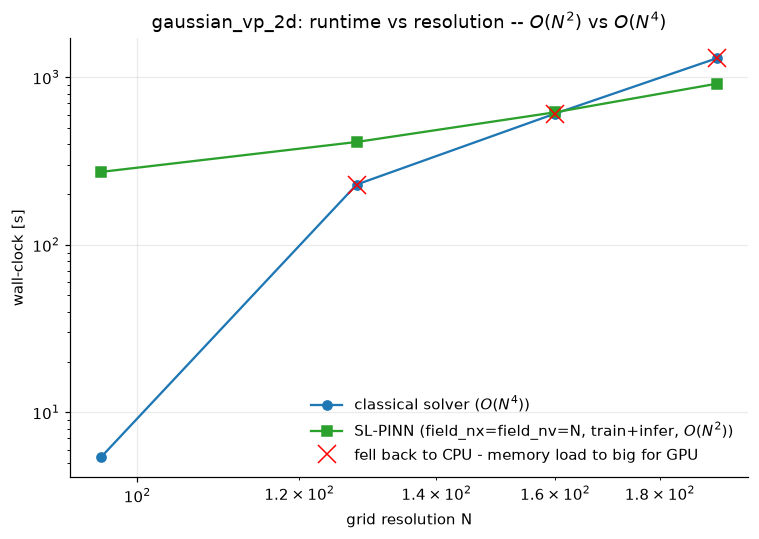

SL-PINN (field grid matched to N) becomes cheaper than the classical solver at N=192: 917.59s vs 1302.62s
(fixed-field-grid SL-PINN line crosses the solver between N=96 and N=128)


In [21]:
pinn_row = acc_rows[-1]
pinn_total = pinn_row["wall_time_total_s"]

report_dir = OUT / "report"
(report_dir / "figures").mkdir(parents=True, exist_ok=True)
(report_dir / "tables").mkdir(parents=True, exist_ok=True)

all_rows = (list(sweep_rows) + list(acc_rows) + list(slpinn_sweep_rows) + [{
    "method": "slpinn_jax_fixed_field", "n": None, "device_used": None, "fell_back": False,
    "wall_time_train_s": trainer.train_time, "wall_time_infer_s": infer_time,
    "wall_time_total_s": pinn_total, "rel_l2_f": pinn_row["rel_l2_f"],
    "problem": trainer.problem.name, "dtype": "float32/64 mixed",
}])
with open(report_dir / "tables" / "crossover_jax.json", "w") as fh:
    json.dump(all_rows, fh, indent=1, default=str)

fig, ax = plt.subplots(figsize=(7, 5))
solver_pts = [(r["n"], r["wall_time_solve_s"]) for r in sweep_rows
             if r.get("wall_time_solve_s") is not None]
solver_pts.sort()
ax.loglog([p[0] for p in solver_pts], [p[1] for p in solver_pts], "o-",
          label=f"classical solver ($O(N^4)$)")
fell = [p for p, r in zip(solver_pts, sweep_rows) if r.get("fell_back")]

slpinn_pts = sorted((r["n"], r["wall_time_total_s"]) for r in slpinn_sweep_rows)
ax.loglog([p[0] for p in slpinn_pts], [p[1] for p in slpinn_pts], "s-", color="C2",
          label=f"SL-PINN (field_nx=field_nv=N, train+infer, $O(N^2)$)")

if fell:
    ax.loglog([p[0] for p in fell], [p[1] for p in fell], "x", color="red",
              markersize=12, label="fell back to CPU - memory load to big for GPU")
ax.set_xlabel("grid resolution N")
ax.set_ylabel("wall-clock [s]")
ax.set_title(f"{trainer.problem.name}: runtime vs resolution -- $O(N^2)$ vs $O(N^4)$")
ax.legend()
fig.tight_layout()
fig.savefig(report_dir / "figures" / "crossover_jax.png")
fig.savefig(report_dir / "figures" / "crossover_jax.pdf")
plt.show()

# Both curves are genuinely indexed by the same N (GRID_SIZES), so compare pairwise
# at matched N rather than against a single flat number.
solver_by_n = dict(solver_pts)
slpinn_by_n = dict(slpinn_pts)
common_ns = sorted(set(solver_by_n) & set(slpinn_by_n))
crossing_n = next((n for n in common_ns if slpinn_by_n[n] <= solver_by_n[n]), None)
if crossing_n is not None:
    print(f"SL-PINN (field grid matched to N) becomes cheaper than the classical solver at "
          f"N={crossing_n}: {slpinn_by_n[crossing_n]:.2f}s vs {solver_by_n[crossing_n]:.2f}s")
else:
    print("the resolution-matched SL-PINN sweep stayed more expensive than the classical solver "
          "over the tested N range -- report this honestly rather than cherry-picking; a larger "
          "GRID_SIZES sweep (set QUICK=False) may be needed to see the O(N^2) vs O(N^4) crossing.")

crossing = [p for p in solver_pts if p[1] >= pinn_total]
if crossing:
    print(f"(fixed-field-grid SL-PINN line crosses the solver between "
          f"N={max((p[0] for p in solver_pts if p[1] < pinn_total), default='?')} and N={crossing[0][0]})")
